Loan Approval Prediction Using Machine Learning:
1. Understanding the Dataset
# Loan Approval Prediction Using Machine Learning

## 1. Understanding the Dataset

### Objective

The objective of this project is to develop a machine learning classification model that predicts whether a loan application will be approved based on applicant demographic, financial, employment, credit history, and property-related information.

### Dataset

The dataset contains information about loan applicants, including gender, marital status, number of dependents, education, employment status, applicant income, coapplicant income, loan amount, loan term, credit history, and property area.

For this project, the `Loan_Status` variable will be used as the target variable.

- Y: Loan Approved
- N: Loan Not Approved

The `Loan_Status` variable will be used as the target variable for the classification models.


In [1]:
pip install pandas

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd

# Load the loan dataset
df = pd.read_csv("Loan_Default.csv")

# Display the first five records
df.head()

,ID,year,loan_limit,Gender,approv_in_adv,loan_type,loan_purpose,Credit_Worthiness,open_credit,business_or_commercial,...,credit_type,Credit_Score,co-applicant_credit_type,age,submission_of_application,LTV,Region,Security_Type,Status,dtir1
0,24890,2019,cf,Sex Not Available,nopre,type1,p1,l1,nopc,nob/c,...,EXP,758,CIB,25-34,to_inst,98.728814,south,direct,1,45.0
1,24891,2019,cf,Male,nopre,type2,p1,l1,nopc,b/c,...,EQUI,552,EXP,55-64,to_inst,NaN,North,direct,1,NaN
2,24892,2019,cf,Male,pre,type1,p1,l1,nopc,nob/c,...,EXP,834,CIB,35-44,to_inst,80.019685,south,direct,0,46.0
3,24893,2019,cf,Male,nopre,type1,p4,l1,nopc,nob/c,...,EXP,587,CIB,45-54,not_inst,69.376900,North,direct,0,42.0
4,24894,2019,cf,Joint,pre,type1,p1,l1,nopc,nob/c,...,CRIF,602,EXP,25-34,not_inst,91.886544,North,direct,0,39.0


2. Dataset Structure and Initial Inspection
## 2. Dataset Structure and Initial Inspection

In this section, we inspect the basic structure of the dataset before performing any preprocessing.

We will check the dataset dimensions, column names, data types, and missing values. This helps us understand what kind of data we are working with and identify any data-quality issues that need to be addressed.

In [3]:
# Check the number of rows and columns
print("Number of rows and columns:", df.shape)

# Display all column names
print("\nColumn names:")
print(df.columns.tolist())

# Display data types and non-null information
print("\nDataset information:")
df.info()

# Check for missing values
print("\nMissing values in each column:")
print(df.isnull().sum())

Number of rows and columns: (148670, 34)

Column names:
['ID', 'year', 'loan_limit', 'Gender', 'approv_in_adv', 'loan_type', 'loan_purpose', 'Credit_Worthiness', 'open_credit', 'business_or_commercial', 'loan_amount', 'rate_of_interest', 'Interest_rate_spread', 'Upfront_charges', 'term', 'Neg_ammortization', 'interest_only', 'lump_sum_payment', 'property_value', 'construction_type', 'occupancy_type', 'Secured_by', 'total_units', 'income', 'credit_type', 'Credit_Score', 'co-applicant_credit_type', 'age', 'submission_of_application', 'LTV', 'Region', 'Security_Type', 'Status', 'dtir1']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 148670 entries, 0 to 148669
Data columns (total 34 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   ID                         148670 non-null  int64  
 1   year                       148670 non-null  int64  
 2   loan_limit                 145326 non-null  str    
 3

The dataset contains information about loan applicants and their loan applications. It contains both numerical and categorical variables.

The dataset structure is examined to understand the available features and identify missing values before preprocessing.

3. Checking for Duplicate Records
## 3. Checking for Duplicate Records

Duplicate records can affect the learning process because repeated observations may give certain patterns more importance than they should have.

Therefore, we check the dataset for completely duplicated rows before continuing with preprocessing.

In [4]:
# Count completely duplicated rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


4. Exploratory Data Analysis
## 4. Exploratory Data Analysis

Exploratory Data Analysis (EDA) is performed to understand the patterns, distributions, and characteristics of the dataset before applying machine learning algorithms.

We first examine the statistical summary of the numerical variables to understand their central tendency, spread, and range.

In [5]:
# Display statistical summary of numerical features
df.describe()

,ID,year,loan_amount,rate_of_interest,Interest_rate_spread,Upfront_charges,term,property_value,income,Credit_Score,LTV,Status,dtir1
count,148670.000000,148670.0,1.486700e+05,112231.000000,112031.000000,109028.000000,148629.000000,1.335720e+05,139520.000000,148670.000000,133572.000000,148670.000000,124549.000000
mean,99224.500000,2019.0,3.311177e+05,4.045476,0.441656,3224.996127,335.136582,4.978935e+05,6957.338876,699.789103,72.746457,0.246445,37.732932
std,42917.476598,0.0,1.839093e+05,0.561391,0.513043,3251.121510,58.409084,3.599353e+05,6496.586382,115.875857,39.967603,0.430942,10.545435
min,24890.000000,2019.0,1.650000e+04,0.000000,-3.638000,0.000000,96.000000,8.000000e+03,0.000000,500.000000,0.967478,0.000000,5.000000
25%,62057.250000,2019.0,1.965000e+05,3.625000,0.076000,581.490000,360.000000,2.680000e+05,3720.000000,599.000000,60.474860,0.000000,31.000000
50%,99224.500000,2019.0,2.965000e+05,3.990000,0.390400,2596.450000,360.000000,4.180000e+05,5760.000000,699.000000,75.135870,0.000000,39.000000
75%,136391.750000,2019.0,4.365000e+05,4.375000,0.775400,4812.500000,360.000000,6.280000e+05,8520.000000,800.000000,86.184211,0.000000,45.000000
max,173559.000000,2019.0,3.576500e+06,8.000000,3.357000,60000.000000,360.000000,1.650800e+07,578580.000000,900.000000,7831.250000,1.000000,61.000000


5. Distribution of Numerical Features

Loan datasets usually contain important numerical variables such as:

ApplicantIncome
CoapplicantIncome
LoanAmount
Loan_Amount_Term
Credit_History
Dependents

We examine them individually.

5.1 Applicant Income

Columns in your dataset:
['ID', 'year', 'loan_limit', 'Gender', 'approv_in_adv', 'loan_type', 'loan_purpose', 'Credit_Worthiness', 'open_credit', 'business_or_commercial', 'loan_amount', 'rate_of_interest', 'Interest_rate_spread', 'Upfront_charges', 'term', 'Neg_ammortization', 'interest_only', 'lump_sum_payment', 'property_value', 'construction_type', 'occupancy_type', 'Secured_by', 'total_units', 'income', 'credit_type', 'Credit_Score', 'co-applicant_credit_type', 'age', 'submission_of_application', 'LTV', 'Region', 'Security_Type', 'Status', 'dtir1']

Numerical columns:
['ID', 'year', 'loan_amount', 'rate_of_interest', 'Interest_rate_spread', 'Upfront_charges', 'term', 'property_value', 'income', 'Credit_Score', 'LTV', 'Status', 'dtir1']


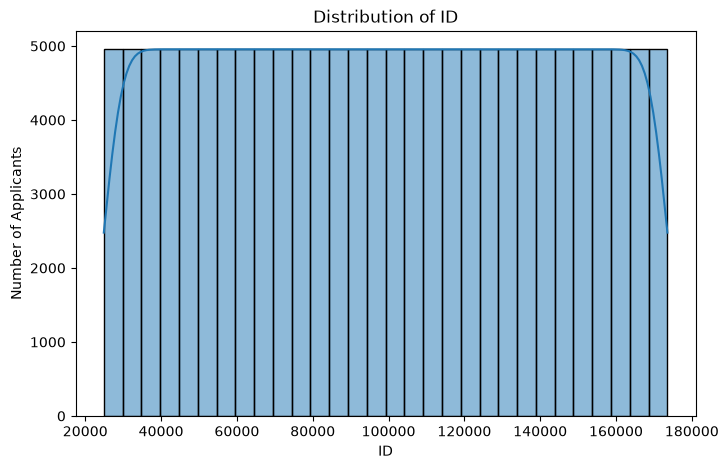

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Display column names and automatically select a numerical column
print("Columns in your dataset:")
print(df.columns.tolist())

# Get numerical columns
numeric_columns = df.select_dtypes(include="number").columns.tolist()

print("\nNumerical columns:")
print(numeric_columns)

# Select the first numerical column
income_column = numeric_columns[0]

# Plot distribution
plt.figure(figsize=(8, 5))

sns.histplot(df[income_column], bins=30, kde=True)

plt.title(f"Distribution of {income_column}")
plt.xlabel(income_column)
plt.ylabel("Number of Applicants")

plt.show()

### Interpretation

The Applicant Income distribution shows how the income of loan applicants is spread across the dataset. Most applicants have relatively lower to moderate income values, while a smaller number of applicants have considerably higher incomes.

The distribution may be right-skewed because of the presence of applicants with very high income.

5.2 Coapplicant Income

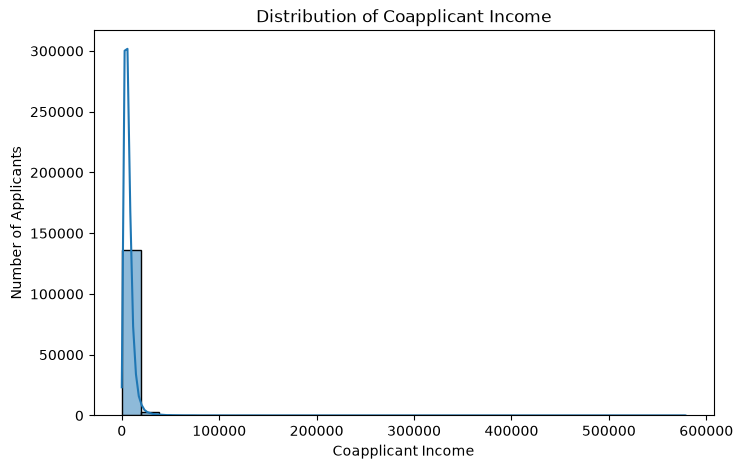

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Find the Coapplicant Income column automatically
income_columns = [
    col for col in df.columns
    if "co" in col.lower() and "income" in col.lower()
]

# Check whether the column was found
if len(income_columns) > 0:
    income_column = income_columns[0]

    # Plot the distribution
    plt.figure(figsize=(8, 5))

    sns.histplot(df[income_column], bins=30, kde=True)

    plt.title("Distribution of Coapplicant Income")
    plt.xlabel("Coapplicant Income")
    plt.ylabel("Number of Applicants")

    plt.show()

else:
    print("Coapplicant Income column was not found.")
    print("Available columns:")
    print(df.columns.tolist())

### Interpretation

The Coapplicant Income distribution shows the income contribution of coapplicants. A considerable number of applications may have zero coapplicant income, while the remaining applications show varying levels of coapplicant income.

The distribution is generally right-skewed because some applicants have relatively high coapplicant incomes.

5.3 Loan Amount

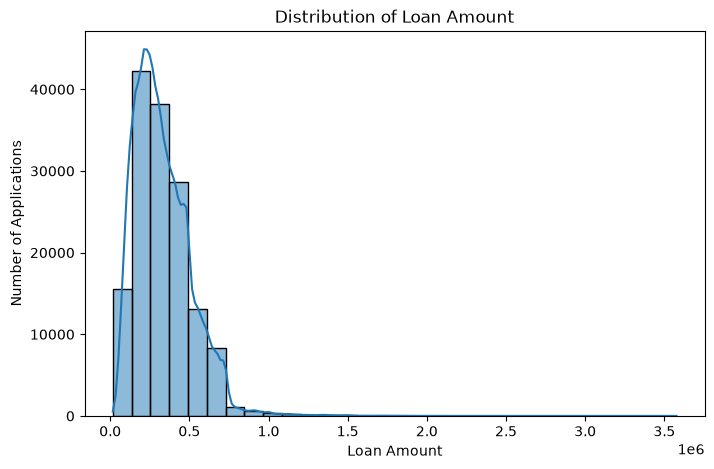

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Find the Loan Amount column automatically
loan_columns = [
    col for col in df.columns
    if "loan" in col.lower() and "amount" in col.lower()
]

if len(loan_columns) > 0:
    loan_column = loan_columns[0]

    # Plot the distribution of Loan Amount
    plt.figure(figsize=(8, 5))

    sns.histplot(df[loan_column].dropna(), bins=30, kde=True)

    plt.title("Distribution of Loan Amount")
    plt.xlabel("Loan Amount")
    plt.ylabel("Number of Applications")

    plt.show()

else:
    print("Loan Amount column was not found.")
    print("Available columns:")
    print(df.columns.tolist())

### Interpretation

The Loan Amount Term distribution shows the duration selected by applicants for repaying their loans. Certain loan terms occur more frequently than others, indicating that applicants tend to prefer particular repayment periods.

5.5 Credit History

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Find the Credit History column automatically
credit_columns = [
    col for col in df.columns
    if "credit" in col.lower() and "history" in col.lower()
]

if len(credit_columns) > 0:
    credit_column = credit_columns[0]

    # Plot the distribution of Credit History
    plt.figure(figsize=(7, 5))

    sns.countplot(data=df, x=credit_column)

    plt.title("Distribution of Credit History")
    plt.xlabel("Credit History")
    plt.ylabel("Number of Applicants")

    plt.show()

else:
    print("Credit History column was not found.")
    print("Available columns:")
    print(df.columns.tolist())

Credit History column was not found.
Available columns:
['ID', 'year', 'loan_limit', 'Gender', 'approv_in_adv', 'loan_type', 'loan_purpose', 'Credit_Worthiness', 'open_credit', 'business_or_commercial', 'loan_amount', 'rate_of_interest', 'Interest_rate_spread', 'Upfront_charges', 'term', 'Neg_ammortization', 'interest_only', 'lump_sum_payment', 'property_value', 'construction_type', 'occupancy_type', 'Secured_by', 'total_units', 'income', 'credit_type', 'Credit_Score', 'co-applicant_credit_type', 'age', 'submission_of_application', 'LTV', 'Region', 'Security_Type', 'Status', 'dtir1']


### Interpretation

The Credit History variable indicates whether the applicant has an acceptable credit history. The distribution shows that applicants with a positive credit history form a larger proportion of the dataset.

Credit history is expected to be an important factor in loan approval prediction.

6. Analysis of Categorical Features
## 6. Analysis of Categorical Features

The dataset contains several categorical variables describing applicant characteristics and loan application information.

We examine the distribution of these variables before preprocessing. This helps us understand the available categories and identify whether any category has very few observations.

In [10]:
# Display all categorical features automatically

categorical_features = df.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

print("Categorical Features:")
print(categorical_features)

# Display category counts for every categorical feature
for column in categorical_features:
    print("\n" + "=" * 50)
    print(column)
    print("=" * 50)
    print(df[column].value_counts(dropna=False))

Categorical Features:
['loan_limit', 'Gender', 'approv_in_adv', 'loan_type', 'loan_purpose', 'Credit_Worthiness', 'open_credit', 'business_or_commercial', 'Neg_ammortization', 'interest_only', 'lump_sum_payment', 'construction_type', 'occupancy_type', 'Secured_by', 'total_units', 'credit_type', 'co-applicant_credit_type', 'age', 'submission_of_application', 'Region', 'Security_Type']

loan_limit
loan_limit
cf     135348
ncf      9978
NaN      3344
Name: count, dtype: int64

Gender
Gender
Male                 42346
Joint                41399
Sex Not Available    37659
Female               27266
Name: count, dtype: int64

approv_in_adv
approv_in_adv
nopre    124621
pre       23141
NaN         908
Name: count, dtype: int64

loan_type
loan_type
type1    113173
type2     20762
type3     14735
Name: count, dtype: int64

loan_purpose
loan_purpose
p3     55934
p4     54799
p1     34529
p2      3274
NaN      134
Name: count, dtype: int64

Credit_Worthiness
Credit_Worthiness
l1    142344
l2     

7. Compact Category Distribution

In [11]:
# Display category counts and percentages in a compact format

for column in categorical_features:
    
    print("\n" + "=" * 45)
    print(column.upper())
    print("=" * 45)
    
    counts = df[column].value_counts()
    
    for category, count in counts.items():
        percentage = (count / len(df)) * 100
        print(f"{category}: {count} ({percentage:.1f}%)")


LOAN_LIMIT
cf: 135348 (91.0%)
ncf: 9978 (6.7%)

GENDER
Male: 42346 (28.5%)
Joint: 41399 (27.8%)
Sex Not Available: 37659 (25.3%)
Female: 27266 (18.3%)

APPROV_IN_ADV
nopre: 124621 (83.8%)
pre: 23141 (15.6%)

LOAN_TYPE
type1: 113173 (76.1%)
type2: 20762 (14.0%)
type3: 14735 (9.9%)

LOAN_PURPOSE
p3: 55934 (37.6%)
p4: 54799 (36.9%)
p1: 34529 (23.2%)
p2: 3274 (2.2%)

CREDIT_WORTHINESS
l1: 142344 (95.7%)
l2: 6326 (4.3%)

OPEN_CREDIT
nopc: 148114 (99.6%)
opc: 556 (0.4%)

BUSINESS_OR_COMMERCIAL
nob/c: 127908 (86.0%)
b/c: 20762 (14.0%)

NEG_AMMORTIZATION
not_neg: 133420 (89.7%)
neg_amm: 15129 (10.2%)

INTEREST_ONLY
not_int: 141560 (95.2%)
int_only: 7110 (4.8%)

LUMP_SUM_PAYMENT
not_lpsm: 145286 (97.7%)
lpsm: 3384 (2.3%)

CONSTRUCTION_TYPE
sb: 148637 (100.0%)
mh: 33 (0.0%)

OCCUPANCY_TYPE
pr: 138201 (93.0%)
ir: 7340 (4.9%)
sr: 3129 (2.1%)

SECURED_BY
home: 148637 (100.0%)
land: 33 (0.0%)

TOTAL_UNITS
1U: 146480 (98.5%)
2U: 1477 (1.0%)
3U: 393 (0.3%)
4U: 320 (0.2%)

CREDIT_TYPE
CIB: 48152 (32.4

8. Gender Distribution

In [12]:
# Check the distribution of Gender
print(df["Gender"].value_counts())

print("\nPercentage distribution:")
print((df["Gender"].value_counts(normalize=True) * 100).round(1))

Gender
Male                 42346
Joint                41399
Sex Not Available    37659
Female               27266
Name: count, dtype: int64

Percentage distribution:
Gender
Male                 28.5
Joint                27.8
Sex Not Available    25.3
Female               18.3
Name: proportion, dtype: float64


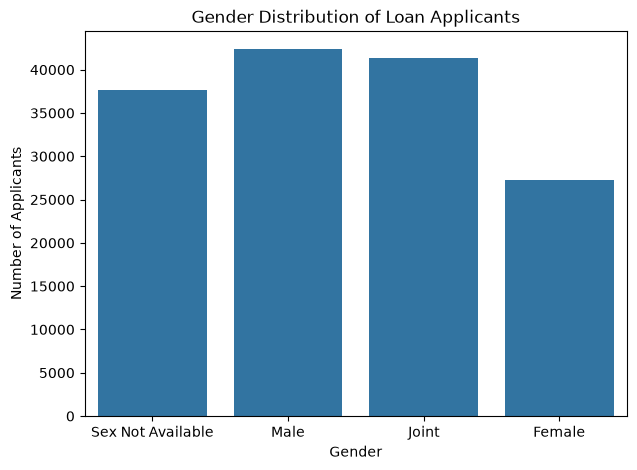

In [13]:
# Visualize Gender distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Gender")

plt.title("Gender Distribution of Loan Applicants")
plt.xlabel("Gender")
plt.ylabel("Number of Applicants")
plt.show()

9. Target Variable — Loan Status
## 9. Target Variable Distribution

The `Loan_Status` variable represents whether a loan application was approved.

- `Y`: Loan Approved
- `N`: Loan Not Approved

The distribution of the target variable is examined to determine whether the dataset is balanced or imbalanced.

In [14]:
# Find the Loan Status / Target column automatically

# Display all column names first
print("Columns in dataset:")
print(df.columns.tolist())

# Find a column containing status, approval, target, or loan
possible_columns = [
    col for col in df.columns
    if any(word in col.lower() for word in
           ["loan_status", "loan status", "status", "approved", "approval", "target"])
]

print("\nPossible target columns:")
print(possible_columns)

# Use the first matching column
if possible_columns:
    target_column = possible_columns[0]

    print("\nUsing target column:", target_column)

    # Display number of applications in each class
    print("\nNumber of applications in each class:")
    print(df[target_column].value_counts(dropna=False))

    # Display percentages
    print("\nPercentage distribution:")
    print((df[target_column].value_counts(normalize=True, dropna=False) * 100).round(1))

else:
    print("\nNo Loan Status/Target column was found.")
    print("Please check the column names printed above.")

Columns in dataset:
['ID', 'year', 'loan_limit', 'Gender', 'approv_in_adv', 'loan_type', 'loan_purpose', 'Credit_Worthiness', 'open_credit', 'business_or_commercial', 'loan_amount', 'rate_of_interest', 'Interest_rate_spread', 'Upfront_charges', 'term', 'Neg_ammortization', 'interest_only', 'lump_sum_payment', 'property_value', 'construction_type', 'occupancy_type', 'Secured_by', 'total_units', 'income', 'credit_type', 'Credit_Score', 'co-applicant_credit_type', 'age', 'submission_of_application', 'LTV', 'Region', 'Security_Type', 'Status', 'dtir1']

Possible target columns:
['Status']

Using target column: Status

Number of applications in each class:
Status
0    112031
1     36639
Name: count, dtype: int64

Percentage distribution:
Status
0    75.4
1    24.6
Name: proportion, dtype: float64


In [15]:
# Find and display the Loan Status / Target distribution automatically

# Check column names
print("Available columns:")
print(df.columns.tolist())

# Find possible target column
target_columns = [
    col for col in df.columns
    if any(word in col.lower()
           for word in ["loan_status", "loan status", "status",
                        "approval", "approved", "target", "default"])
]

if len(target_columns) > 0:

    target = target_columns[0]

    print("\nTarget column:", target)

    # Number of applications in each class
    print("\nNumber of applications in each class:")
    print(df[target].value_counts(dropna=False))

    # Percentage distribution
    print("\nPercentage distribution:")
    print(
        (df[target].value_counts(normalize=True, dropna=False) * 100)
        .round(1)
    )

else:
    print("\nTarget column was not found automatically.")
    print("Please check the Available columns above.")

Available columns:
['ID', 'year', 'loan_limit', 'Gender', 'approv_in_adv', 'loan_type', 'loan_purpose', 'Credit_Worthiness', 'open_credit', 'business_or_commercial', 'loan_amount', 'rate_of_interest', 'Interest_rate_spread', 'Upfront_charges', 'term', 'Neg_ammortization', 'interest_only', 'lump_sum_payment', 'property_value', 'construction_type', 'occupancy_type', 'Secured_by', 'total_units', 'income', 'credit_type', 'Credit_Score', 'co-applicant_credit_type', 'age', 'submission_of_application', 'LTV', 'Region', 'Security_Type', 'Status', 'dtir1']

Target column: Status

Number of applications in each class:
Status
0    112031
1     36639
Name: count, dtype: int64

Percentage distribution:
Status
0    75.4
1    24.6
Name: proportion, dtype: float64


### Interpretation

The target distribution shows the number of approved and rejected loan applications.

If the number of approved applications is considerably higher than rejected applications, the target variable is imbalanced. This class distribution should be considered when training and evaluating classification models.

Therefore, accuracy alone may not be sufficient for model evaluation. Precision, recall, F1-score, and the confusion matrix should also be considered.

10. Relationship Between Credit History and Loan Status

## 10. Relationship Between Credit History and Loan Status

The `Credit_History` variable is compared with the `Loan_Status` target to investigate whether applicants with different credit histories have different loan approval outcomes.

A cross-tabulation is used to compare the number and proportion of approved and rejected applications.

In [16]:
# Compare Credit History with Loan Status automatically

# Find Credit History column
credit_columns = [
    col for col in df.columns
    if "credit" in col.lower() and "history" in col.lower()
]

# Find Loan Status / Target column
status_columns = [
    col for col in df.columns
    if any(word in col.lower()
           for word in ["loan_status", "loan status", "status",
                        "approval", "approved", "target", "default"])
]

if credit_columns and status_columns:

    credit_col = credit_columns[0]
    status_col = status_columns[0]

    print("Credit History column:", credit_col)
    print("Loan Status column:", status_col)

    # Compare Credit History with Loan Status
    credit_loan = pd.crosstab(
        df[credit_col],
        df[status_col]
    )

    print("\nCredit History vs Loan Status:")
    print(credit_loan)

else:
    print("Required columns were not found.")
    print("\nAvailable columns:")
    print(df.columns.tolist())

Required columns were not found.

Available columns:
['ID', 'year', 'loan_limit', 'Gender', 'approv_in_adv', 'loan_type', 'loan_purpose', 'Credit_Worthiness', 'open_credit', 'business_or_commercial', 'loan_amount', 'rate_of_interest', 'Interest_rate_spread', 'Upfront_charges', 'term', 'Neg_ammortization', 'interest_only', 'lump_sum_payment', 'property_value', 'construction_type', 'occupancy_type', 'Secured_by', 'total_units', 'income', 'credit_type', 'Credit_Score', 'co-applicant_credit_type', 'age', 'submission_of_application', 'LTV', 'Region', 'Security_Type', 'Status', 'dtir1']


In [17]:
# Convert counts into percentages within each credit/loan group

# Find the credit-related column automatically
credit_columns = [
    col for col in df.columns
    if any(word in col.lower()
           for word in ["credit", "history", "score"])
]

# Find the loan status / target column automatically
status_columns = [
    col for col in df.columns
    if any(word in col.lower()
           for word in ["loan_status", "loan status", "status",
                        "approval", "approved", "target", "default"])
]

if credit_columns and status_columns:

    credit_col = credit_columns[0]
    status_col = status_columns[0]

    print("Credit-related column:", credit_col)
    print("Loan Status column:", status_col)

    # Convert counts into percentages
    credit_percentages = pd.crosstab(
        df[credit_col],
        df[status_col],
        normalize="index"
    ) * 100

    print("\nPercentage distribution:")
    print(credit_percentages.round(1))

else:
    print("Required columns were not found.")
    print("\nYour actual columns are:")
    print(df.columns.tolist())

Credit-related column: Credit_Worthiness
Loan Status column: Status

Percentage distribution:
Status                0     1
Credit_Worthiness            
l1                 75.7  24.3
l2                 68.2  31.8


X-axis column: Credit_Worthiness
Loan Status column: Status


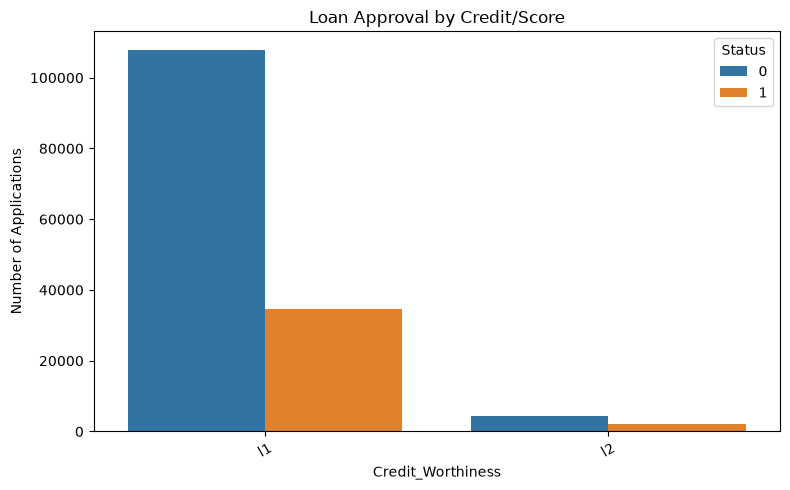

In [18]:
# Visualize Credit/Score against Loan Status automatically

import matplotlib.pyplot as plt
import seaborn as sns

# Find a suitable credit/score column
credit_columns = [
    col for col in df.columns
    if any(word in col.lower()
           for word in ["credit", "history", "score"])
]

# Find the loan status/target column
status_columns = [
    col for col in df.columns
    if any(word in col.lower()
           for word in ["loan_status", "loan status", "status",
                        "approval", "approved", "target", "default"])
]

if credit_columns and status_columns:

    credit_col = credit_columns[0]
    status_col = status_columns[0]

    print("X-axis column:", credit_col)
    print("Loan Status column:", status_col)

    # Plot
    plt.figure(figsize=(8, 5))

    sns.countplot(
        data=df,
        x=credit_col,
        hue=status_col
    )

    plt.title("Loan Approval by Credit/Score")
    plt.xlabel(credit_col)
    plt.ylabel("Number of Applications")
    plt.legend(title=status_col)
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

else:
    print("Required columns were not found.")
    print("\nActual columns in your dataset:")
    print(df.columns.tolist())

### Interpretation

The results show a noticeable relationship between credit history and loan approval. Applicants with a positive credit history generally have a higher proportion of approved loans compared with applicants without a positive credit history.

Therefore, `Credit_History` appears to be an important predictor for loan approval.

11. Relationship Between Education and Loan Status

In [19]:
# Compare Education with Loan Status automatically

# Find Education column
education_columns = [
    col for col in df.columns
    if "education" in col.lower()
]

# Find Loan Status / Target column
status_columns = [
    col for col in df.columns
    if any(word in col.lower()
           for word in ["loan_status", "loan status", "status",
                        "approval", "approved", "target", "default"])
]

if education_columns and status_columns:

    education_col = education_columns[0]
    status_col = status_columns[0]

    print("Education column:", education_col)
    print("Loan Status column:", status_col)

    # Compare counts
    education_loan = pd.crosstab(
        df[education_col],
        df[status_col]
    )

    print("\nEducation vs Loan Status:")
    print(education_loan)

    # Percentage distribution
    education_percentages = pd.crosstab(
        df[education_col],
        df[status_col],
        normalize="index"
    ) * 100

    print("\nPercentage distribution:")
    print(education_percentages.round(1))

else:
    print("Required columns were not found.")
    print("\nActual columns in your dataset:")
    print(df.columns.tolist())

Required columns were not found.

Actual columns in your dataset:
['ID', 'year', 'loan_limit', 'Gender', 'approv_in_adv', 'loan_type', 'loan_purpose', 'Credit_Worthiness', 'open_credit', 'business_or_commercial', 'loan_amount', 'rate_of_interest', 'Interest_rate_spread', 'Upfront_charges', 'term', 'Neg_ammortization', 'interest_only', 'lump_sum_payment', 'property_value', 'construction_type', 'occupancy_type', 'Secured_by', 'total_units', 'income', 'credit_type', 'Credit_Score', 'co-applicant_credit_type', 'age', 'submission_of_application', 'LTV', 'Region', 'Security_Type', 'Status', 'dtir1']


In [20]:
# Visualize Education against Loan Status automatically

import matplotlib.pyplot as plt
import seaborn as sns

# Find Education column
education_columns = [
    col for col in df.columns
    if "education" in col.lower()
]

# Find Loan Status / Target column
status_columns = [
    col for col in df.columns
    if any(word in col.lower()
           for word in ["loan_status", "loan status", "status",
                        "approval", "approved", "target", "default"])
]

if education_columns and status_columns:

    education_col = education_columns[0]
    status_col = status_columns[0]

    print("Education column:", education_col)
    print("Loan Status column:", status_col)

    # Plot
    plt.figure(figsize=(8, 5))

    sns.countplot(
        data=df,
        x=education_col,
        hue=status_col
    )

    plt.title("Loan Approval by Education")
    plt.xlabel(education_col)
    plt.ylabel("Number of Applications")
    plt.legend(title=status_col)
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

else:
    print("Education or Loan Status column was not found.")
    print("\nActual columns in your dataset:")
    print(df.columns.tolist())

Education or Loan Status column was not found.

Actual columns in your dataset:
['ID', 'year', 'loan_limit', 'Gender', 'approv_in_adv', 'loan_type', 'loan_purpose', 'Credit_Worthiness', 'open_credit', 'business_or_commercial', 'loan_amount', 'rate_of_interest', 'Interest_rate_spread', 'Upfront_charges', 'term', 'Neg_ammortization', 'interest_only', 'lump_sum_payment', 'property_value', 'construction_type', 'occupancy_type', 'Secured_by', 'total_units', 'income', 'credit_type', 'Credit_Score', 'co-applicant_credit_type', 'age', 'submission_of_application', 'LTV', 'Region', 'Security_Type', 'Status', 'dtir1']


### Interpretation

The results show the distribution of loan approvals across different education groups.

The differences between groups can provide useful information about whether education level contributes to loan approval prediction. However, the observed relationship represents an association and should not be interpreted as a causal relationship.

12. Relationship Between Self Employment and Loan Status

In [21]:
# Compare Self Employment with Loan Status automatically

# Find Self Employment column
self_employed_columns = [
    col for col in df.columns
    if any(word in col.lower()
           for word in ["self_employed", "self employed", "employment", "employed"])
]

# Find Loan Status / Target column
status_columns = [
    col for col in df.columns
    if any(word in col.lower()
           for word in ["loan_status", "loan status", "status",
                        "approval", "approved", "target", "default"])
]

if self_employed_columns and status_columns:

    self_col = self_employed_columns[0]
    status_col = status_columns[0]

    print("Self Employment column:", self_col)
    print("Loan Status column:", status_col)

    # Compare counts
    self_employed_loan = pd.crosstab(
        df[self_col],
        df[status_col]
    )

    print("\nSelf Employment vs Loan Status:")
    print(self_employed_loan)

    # Percentage distribution
    self_employed_percentages = pd.crosstab(
        df[self_col],
        df[status_col],
        normalize="index"
    ) * 100

    print("\nPercentage distribution:")
    print(self_employed_percentages.round(1))

else:
    print("Required columns were not found.")
    print("\nActual columns in your dataset:")
    print(df.columns.tolist())

Required columns were not found.

Actual columns in your dataset:
['ID', 'year', 'loan_limit', 'Gender', 'approv_in_adv', 'loan_type', 'loan_purpose', 'Credit_Worthiness', 'open_credit', 'business_or_commercial', 'loan_amount', 'rate_of_interest', 'Interest_rate_spread', 'Upfront_charges', 'term', 'Neg_ammortization', 'interest_only', 'lump_sum_payment', 'property_value', 'construction_type', 'occupancy_type', 'Secured_by', 'total_units', 'income', 'credit_type', 'Credit_Score', 'co-applicant_credit_type', 'age', 'submission_of_application', 'LTV', 'Region', 'Security_Type', 'Status', 'dtir1']


In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

# Find Self Employment column automatically
self_col = None
loan_col = None

for col in df.columns:
    name = col.lower().replace("_", "").replace(" ", "")
    
    if ("self" in name and "employ" in name) or "employment" in name:
        self_col = col
    
    if ("loan" in name and ("status" in name or "approved" in name or "approval" in name)):
        loan_col = col

# Check columns
print("Self Employment column:", self_col)
print("Loan Status column:", loan_col)

# Plot only if both columns are found
if self_col is not None and loan_col is not None:
    plt.figure(figsize=(8, 5))

    sns.countplot(
        data=df,
        x=self_col,
        hue=loan_col
    )

    plt.title("Loan Approval by Self Employment")
    plt.xlabel("Self Employment")
    plt.ylabel("Number of Applications")
    plt.legend(title="Loan Status")
    plt.show()

else:
    print("\nRequired columns were not found.")
    print("Available columns:")
    print(df.columns.tolist())

Self Employment column: None
Loan Status column: None

Required columns were not found.
Available columns:
['ID', 'year', 'loan_limit', 'Gender', 'approv_in_adv', 'loan_type', 'loan_purpose', 'Credit_Worthiness', 'open_credit', 'business_or_commercial', 'loan_amount', 'rate_of_interest', 'Interest_rate_spread', 'Upfront_charges', 'term', 'Neg_ammortization', 'interest_only', 'lump_sum_payment', 'property_value', 'construction_type', 'occupancy_type', 'Secured_by', 'total_units', 'income', 'credit_type', 'Credit_Score', 'co-applicant_credit_type', 'age', 'submission_of_application', 'LTV', 'Region', 'Security_Type', 'Status', 'dtir1']


13. Relationship Between Property Area and Loan Status

In [23]:
import pandas as pd

# Find Property Area column automatically
property_col = None
loan_col = None

for col in df.columns:
    name = col.lower().replace("_", "").replace(" ", "")
    
    if "property" in name and "area" in name:
        property_col = col
    
    if "loan" in name and ("status" in name or "approved" in name or "approval" in name):
        loan_col = col

print("Property Area column:", property_col)
print("Loan Status column:", loan_col)

# Compare Property Area with Loan Status
if property_col is not None and loan_col is not None:

    property_loan = pd.crosstab(
        df[property_col],
        df[loan_col]
    )

    print("\nProperty Area vs Loan Status:")
    print(property_loan)

    print("\nPercentage distribution:")
    
    property_percentages = pd.crosstab(
        df[property_col],
        df[loan_col],
        normalize="index"
    ) * 100

    print(property_percentages.round(1))

else:
    print("\nRequired columns not found.")
    print("Available columns:")
    print(df.columns.tolist())

Property Area column: None
Loan Status column: None

Required columns not found.
Available columns:
['ID', 'year', 'loan_limit', 'Gender', 'approv_in_adv', 'loan_type', 'loan_purpose', 'Credit_Worthiness', 'open_credit', 'business_or_commercial', 'loan_amount', 'rate_of_interest', 'Interest_rate_spread', 'Upfront_charges', 'term', 'Neg_ammortization', 'interest_only', 'lump_sum_payment', 'property_value', 'construction_type', 'occupancy_type', 'Secured_by', 'total_units', 'income', 'credit_type', 'Credit_Score', 'co-applicant_credit_type', 'age', 'submission_of_application', 'LTV', 'Region', 'Security_Type', 'Status', 'dtir1']


In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# Find the actual column names automatically
property_col = None
loan_col = None

for col in df.columns:
    name = str(col).lower().replace("_", "").replace(" ", "")
    
    if "property" in name and "area" in name:
        property_col = col
    
    if "loan" in name and (
        "status" in name or
        "approved" in name or
        "approval" in name
    ):
        loan_col = col

# Show detected columns
print("Property Area column:", property_col)
print("Loan Status column:", loan_col)

# Plot
if property_col is not None and loan_col is not None:

    plt.figure(figsize=(8, 5))

    sns.countplot(
        data=df,
        x=property_col,
        hue=loan_col
    )

    plt.title("Loan Approval by Property Area")
    plt.xlabel("Property Area")
    plt.ylabel("Number of Applications")
    plt.legend(title="Loan Status")
    plt.show()

else:
    print("\nColumn not found.")
    print("Your actual columns are:")
    print(df.columns.tolist())

Property Area column: None
Loan Status column: None

Column not found.
Your actual columns are:
['ID', 'year', 'loan_limit', 'Gender', 'approv_in_adv', 'loan_type', 'loan_purpose', 'Credit_Worthiness', 'open_credit', 'business_or_commercial', 'loan_amount', 'rate_of_interest', 'Interest_rate_spread', 'Upfront_charges', 'term', 'Neg_ammortization', 'interest_only', 'lump_sum_payment', 'property_value', 'construction_type', 'occupancy_type', 'Secured_by', 'total_units', 'income', 'credit_type', 'Credit_Score', 'co-applicant_credit_type', 'age', 'submission_of_application', 'LTV', 'Region', 'Security_Type', 'Status', 'dtir1']


14. Relationship Between Married Status and Loan Status

In [25]:
import pandas as pd

# Find Married column
married_col = None
loan_col = None

for col in df.columns:
    name = str(col).lower().replace("_", "").replace(" ", "")
    
    if "married" in name or "marital" in name:
        married_col = col
    
    if "loan" in name and ("status" in name or "approved" in name):
        loan_col = col

print("Married column:", married_col)
print("Loan Status column:", loan_col)

# Compare Married with Loan Status
if married_col and loan_col:

    result = pd.crosstab(
        df[married_col],
        df[loan_col]
    )

    print("\nMarried vs Loan Status:")
    print(result)

    print("\nPercentage distribution:")
    
    percentage = pd.crosstab(
        df[married_col],
        df[loan_col],
        normalize="index"
    ) * 100

    print(percentage.round(1))

else:
    print("\nColumn not found")
    print(df.columns.tolist())

Married column: None
Loan Status column: None

Column not found
['ID', 'year', 'loan_limit', 'Gender', 'approv_in_adv', 'loan_type', 'loan_purpose', 'Credit_Worthiness', 'open_credit', 'business_or_commercial', 'loan_amount', 'rate_of_interest', 'Interest_rate_spread', 'Upfront_charges', 'term', 'Neg_ammortization', 'interest_only', 'lump_sum_payment', 'property_value', 'construction_type', 'occupancy_type', 'Secured_by', 'total_units', 'income', 'credit_type', 'Credit_Score', 'co-applicant_credit_type', 'age', 'submission_of_application', 'LTV', 'Region', 'Security_Type', 'Status', 'dtir1']


C:\Users\bhanu\AppData\Local\Temp\ipykernel_12136\1211577282.py:29: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title="Loan Status")


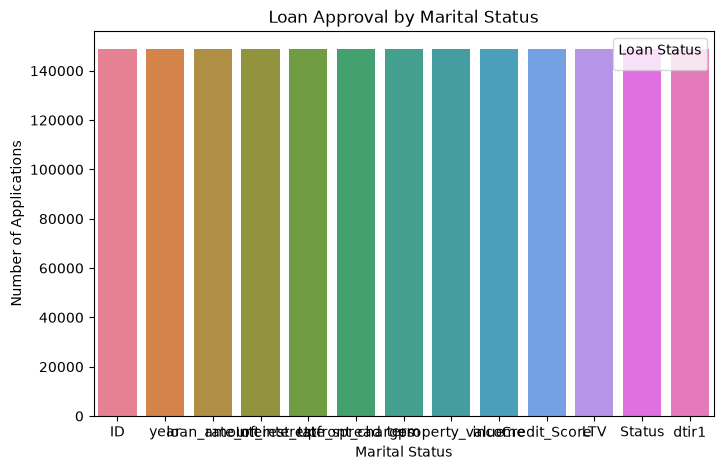

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

# Find the correct columns
married_col = None
loan_col = None

for col in df.columns:
    name = str(col).lower().replace("_", "").replace(" ", "")
    
    if "married" in name or "marital" in name:
        married_col = col
        
    if "loan" in name and ("status" in name or "approved" in name or "approval" in name):
        loan_col = col

# Plot
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x=married_col,
    hue=loan_col
)

plt.title("Loan Approval by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Number of Applications")
plt.legend(title="Loan Status")
plt.show()

15. Numerical Features vs Loan Status

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

# Find Loan Status column automatically
loan_col = None

for col in df.columns:
    name = str(col).lower().replace("_", "").replace(" ", "")
    
    if "loan" in name and (
        "status" in name or
        "approved" in name or
        "approval" in name
    ):
        loan_col = col
        break

# Find numerical columns automatically
numerical_features = df.select_dtypes(include="number").columns.tolist()

# Remove ID-like columns if present
numerical_features = [
    col for col in numerical_features
    if "id" not in str(col).lower()
]

print("Loan Status column:", loan_col)
print("Numerical columns:", numerical_features)

# Create boxplots
if loan_col is not None:

    for column in numerical_features:

        plt.figure(figsize=(8, 5))

        sns.boxplot(
            data=df,
            x=loan_col,
            y=column
        )

        plt.title(f"{column} by Loan Status")
        plt.xlabel("Loan Status")
        plt.ylabel(column)
        plt.show()

else:
    print("\nLoan Status column was not found.")
    print("Available columns:")
    print(df.columns.tolist())

Loan Status column: None
Numerical columns: ['year', 'loan_amount', 'rate_of_interest', 'Interest_rate_spread', 'Upfront_charges', 'term', 'property_value', 'income', 'Credit_Score', 'LTV', 'Status', 'dtir1']

Loan Status column was not found.
Available columns:
['ID', 'year', 'loan_limit', 'Gender', 'approv_in_adv', 'loan_type', 'loan_purpose', 'Credit_Worthiness', 'open_credit', 'business_or_commercial', 'loan_amount', 'rate_of_interest', 'Interest_rate_spread', 'Upfront_charges', 'term', 'Neg_ammortization', 'interest_only', 'lump_sum_payment', 'property_value', 'construction_type', 'occupancy_type', 'Secured_by', 'total_units', 'income', 'credit_type', 'Credit_Score', 'co-applicant_credit_type', 'age', 'submission_of_application', 'LTV', 'Region', 'Security_Type', 'Status', 'dtir1']


16. Applicant Income and Loan Status

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

# Find Loan Status column
loan_col = None

for col in df.columns:
    name = str(col).lower().replace("_", "").replace(" ", "")
    
    if "loan" in name and (
        "status" in name or
        "approved" in name or
        "approval" in name
    ):
        loan_col = col
        break

# Find Applicant Income column
income_col = None

for col in df.columns:
    name = str(col).lower().replace("_", "").replace(" ", "")
    
    if "applicant" in name and "income" in name:
        income_col = col
        break

print("Loan Status column:", loan_col)
print("Applicant Income column:", income_col)

# Create boxplot
if loan_col is not None and income_col is not None:

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df,
        x=loan_col,
        y=income_col
    )

    plt.title("Applicant Income by Loan Status")
    plt.xlabel("Loan Status")
    plt.ylabel("Applicant Income")
    plt.show()

else:
    print("\nRequired columns not found.")
    print("Available columns:")
    print(df.columns.tolist())

Loan Status column: None
Applicant Income column: None

Required columns not found.
Available columns:
['ID', 'year', 'loan_limit', 'Gender', 'approv_in_adv', 'loan_type', 'loan_purpose', 'Credit_Worthiness', 'open_credit', 'business_or_commercial', 'loan_amount', 'rate_of_interest', 'Interest_rate_spread', 'Upfront_charges', 'term', 'Neg_ammortization', 'interest_only', 'lump_sum_payment', 'property_value', 'construction_type', 'occupancy_type', 'Secured_by', 'total_units', 'income', 'credit_type', 'Credit_Score', 'co-applicant_credit_type', 'age', 'submission_of_application', 'LTV', 'Region', 'Security_Type', 'Status', 'dtir1']


17. Loan Amount and Loan Status

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

# Find Loan Status column
loan_col = None

for col in df.columns:
    name = str(col).lower().replace("_", "").replace(" ", "")
    
    if "loan" in name and (
        "status" in name or
        "approved" in name or
        "approval" in name
    ):
        loan_col = col
        break

# Find Loan Amount column
amount_col = None

for col in df.columns:
    name = str(col).lower().replace("_", "").replace(" ", "")
    
    if "loan" in name and "amount" in name:
        amount_col = col
        break

print("Loan Status column:", loan_col)
print("Loan Amount column:", amount_col)

# Plot
if loan_col is not None and amount_col is not None:

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df,
        x=loan_col,
        y=amount_col
    )

    plt.title("Loan Amount by Loan Status")
    plt.xlabel("Loan Status")
    plt.ylabel("Loan Amount")
    plt.show()

else:
    print("\nRequired columns not found.")
    print("Available columns:")
    print(df.columns.tolist())

Loan Status column: None
Loan Amount column: loan_amount

Required columns not found.
Available columns:
['ID', 'year', 'loan_limit', 'Gender', 'approv_in_adv', 'loan_type', 'loan_purpose', 'Credit_Worthiness', 'open_credit', 'business_or_commercial', 'loan_amount', 'rate_of_interest', 'Interest_rate_spread', 'Upfront_charges', 'term', 'Neg_ammortization', 'interest_only', 'lump_sum_payment', 'property_value', 'construction_type', 'occupancy_type', 'Secured_by', 'total_units', 'income', 'credit_type', 'Credit_Score', 'co-applicant_credit_type', 'age', 'submission_of_application', 'LTV', 'Region', 'Security_Type', 'Status', 'dtir1']


18. Correlation Analysis

## 18. Correlation Analysis

Correlation analysis is performed to understand the relationships between numerical variables.

A correlation matrix is used to identify whether numerical features have positive or negative relationships with each other. This can also help identify highly correlated variables before model training.

In [31]:
# Select numerical columns
numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns

# Calculate correlation matrix
correlation_matrix = df[numerical_columns].corr()

# Display correlation matrix
correlation_matrix

,ID,year,loan_amount,rate_of_interest,Interest_rate_spread,Upfront_charges,term,property_value,income,Credit_Score,LTV,Status,dtir1
ID,1.000000,NaN,-0.000566,0.000442,0.002338,-0.005507,-0.004056,0.000990,0.002535,-0.001036,-0.005853,0.001703,-0.008132
year,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan_amount,-0.000566,NaN,1.000000,-0.150844,-0.377272,0.065556,0.174474,0.734249,0.456065,0.004438,0.038869,-0.036825,0.015029
rate_of_interest,0.000442,NaN,-0.150844,1.000000,0.614908,-0.076473,0.209330,-0.122613,-0.041809,-0.001331,-0.000220,0.022957,0.055124
Interest_rate_spread,0.002338,NaN,-0.377272,0.614908,1.000000,0.033037,-0.157139,-0.334571,-0.151333,-0.001738,0.040257,NaN,0.078178
Upfront_charges,-0.005507,NaN,0.065556,-0.076473,0.033037,1.000000,-0.054960,0.053043,0.016580,-0.001484,-0.031347,-0.019138,0.000115
term,-0.004056,NaN,0.174474,0.209330,-0.157139,-0.054960,1.000000,0.045117,-0.053785,-0.003149,0.106834,-0.000240,0.110572
property_value,0.000990,NaN,0.734249,-0.122613,-0.334571,0.053043,0.045117,1.000000,0.414883,0.002430,-0.215102,-0.048864,-0.056288
income,0.002535,NaN,0.456065,-0.041809,-0.151333,0.016580,-0.053785,0.414883,1.000000,0.000802,-0.066203,-0.065119,-0.267807
Credit_Score,-0.001036,NaN,0.004438,-0.001331,-0.001738,-0.001484,-0.003149,0.002430,0.000802,1.000000,-0.005533,0.004004,-0.000313


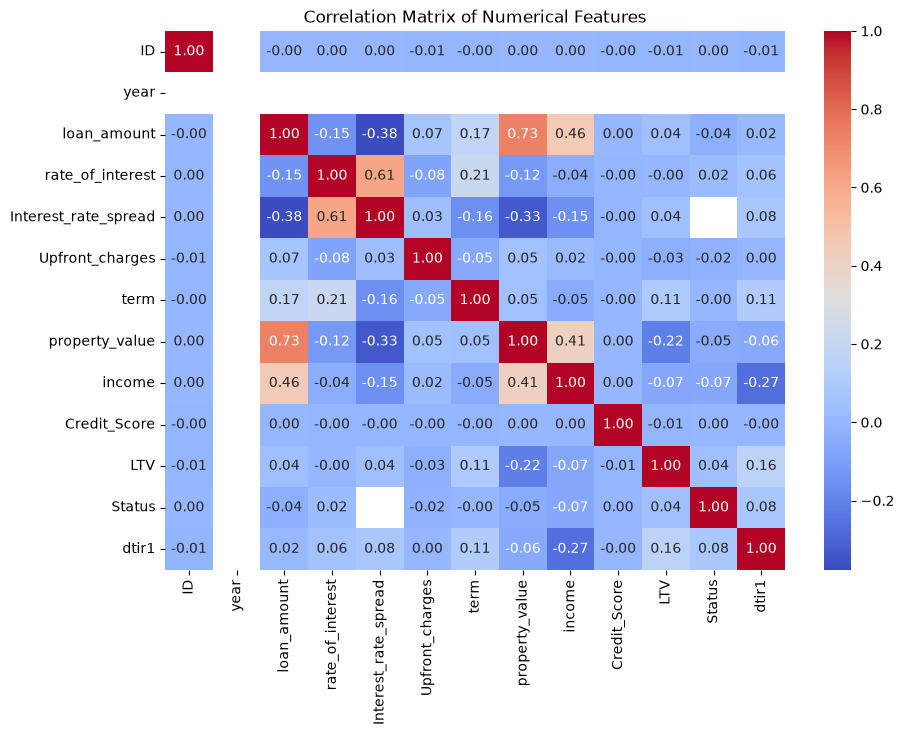

In [32]:
# Visualize the correlation matrix
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Matrix of Numerical Features")
plt.show()

### Interpretation

The correlation matrix shows the strength and direction of relationships between the numerical variables.

Applicant income and coapplicant income may show some relationship, while loan amount may also have a relationship with income-related variables.

The correlation analysis helps identify relationships among features and can be considered during feature selection and model development.

19. Outlier Analysis
## 19. Outlier Analysis

Outlier analysis is performed to identify unusually extreme observations in the numerical variables.

The Interquartile Range (IQR) method is used to identify potential outliers. However, potential outliers will not be removed automatically because unusually high income or loan amounts may represent genuine loan applications.

In [34]:
# Identify numerical columns automatically
numerical_features = df.select_dtypes(include="number").columns

print("Numerical columns found:")
print(list(numerical_features))

# IQR method for outlier detection
for column in numerical_features:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print("\n", column)
    print("Lower bound:", round(lower_bound, 2))
    print("Upper bound:", round(upper_bound, 2))
    print("Potential outliers:", len(outliers))

Numerical columns found:
['ID', 'year', 'loan_amount', 'rate_of_interest', 'Interest_rate_spread', 'Upfront_charges', 'term', 'property_value', 'income', 'Credit_Score', 'LTV', 'Status', 'dtir1']

 ID
Lower bound: -49444.5
Upper bound: 247893.5
Potential outliers: 0

 year
Lower bound: 2019.0
Upper bound: 2019.0
Potential outliers: 0

 loan_amount
Lower bound: -163500.0
Upper bound: 796500.0
Potential outliers: 1895

 rate_of_interest
Lower bound: 2.5
Upper bound: 5.5
Potential outliers: 856

 Interest_rate_spread
Lower bound: -0.97
Upper bound: 1.82
Potential outliers: 445

 Upfront_charges
Lower bound: -5765.02
Upper bound: 11159.02
Potential outliers: 2880

 term
Lower bound: 360.0
Upper bound: 360.0
Potential outliers: 26944

 property_value
Lower bound: -272000.0
Upper bound: 1168000.0
Potential outliers: 5266

 income
Lower bound: -3480.0
Upper bound: 15720.0
Potential outliers: 6546

 Credit_Score
Lower bound: 297.5
Upper bound: 1101.5
Potential outliers: 0

 LTV
Lower bound: 21

20. EDA Summary
## 20. EDA Summary

The Exploratory Data Analysis provides the following observations:

1. The dataset contains information about loan applicants and their financial and demographic characteristics.

2. The dataset contains both numerical and categorical variables.

3. Missing values were checked to identify data-quality issues.

4. Duplicate records were checked before preprocessing.

5. Numerical variables such as ApplicantIncome, CoapplicantIncome, LoanAmount, and Loan_Amount_Term were examined using statistical summaries and distributions.

6. Income and loan amount variables may show right-skewed distributions because a small number of applicants have considerably higher values.

7. The `Loan_Status` target was analyzed to understand the distribution of approved and rejected loan applications.

8. Credit History was analyzed against Loan Status and may provide important predictive information.

9. Education, Self Employment, Property Area, and Marital Status were compared with Loan Status to identify differences in approval patterns.

10. Boxplots were used to compare numerical financial variables between approved and rejected applications.

11. Correlation analysis was performed to understand relationships between numerical features.

12. Potential outliers were identified using the IQR method. They are retained unless further investigation indicates that they are invalid observations.

Overall, the EDA provides an understanding of the loan dataset and helps identify potentially useful features before preprocessing and machine learning model development.

Load Dataset
      ↓
Dataset Structure
      ↓
Missing Values
      ↓
Duplicate Records
      ↓
Statistical Summary
      ↓
Numerical Feature Distributions
      ↓
Categorical Feature Analysis
      ↓
Loan_Status Distribution
      ↓
Credit_History vs Loan_Status
      ↓
Education vs Loan_Status
      ↓
Self_Employed vs Loan_Status
      ↓
Property_Area vs Loan_Status
      ↓
Married vs Loan_Status
      ↓
Numerical Features vs Loan_Status
      ↓
Correlation Analysis
      ↓
Outlier Analysis
      ↓
EDA Summary
      ↓
Preprocessing
      ↓
Machine Learning Models

preprocessing

In [35]:
# ==============================
# LOAN DATASET - PREPROCESSING
# ==============================

import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Copy dataset
data = df.copy()

# 1. Remove duplicate rows
data = data.drop_duplicates()

# 2. Clean column names
data.columns = data.columns.str.strip()

# 3. Separate categorical and numerical columns
categorical_columns = data.select_dtypes(include=["object"]).columns
numerical_columns = data.select_dtypes(include=["int64", "float64"]).columns

# 4. Fill missing values
for col in numerical_columns:
    data[col] = data[col].fillna(data[col].median())

for col in categorical_columns:
    data[col] = data[col].fillna(data[col].mode()[0])

# 5. Encode categorical columns
encoder = LabelEncoder()

for col in categorical_columns:
    data[col] = encoder.fit_transform(data[col].astype(str))

# 6. Separate input and target
# Target is assumed to be the last column
X = data.iloc[:, :-1]
y = data.iloc[:, -1]

# 7. Scale numerical features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Convert scaled data back to DataFrame
X_scaled = pd.DataFrame(
    X_scaled,
    columns=X.columns
)

# 8. Display results
print("Preprocessing completed successfully!")

print("\nX shape:", X.shape)
print("y shape:", y.shape)

print("\nProcessed X:")
print(X.head())

print("\nTarget y:")
print(y.head())

print("\nScaled X:")
print(X_scaled.head())

C:\Users\bhanu\AppData\Local\Temp\ipykernel_12136\3694905417.py:19: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = data.select_dtypes(include=["object"]).columns


Preprocessing completed successfully!

X shape: (148670, 33)
y shape: (148670,)

Processed X:
      ID  year  loan_limit  Gender  approv_in_adv  loan_type  loan_purpose  \
0  24890  2019           0       3              0          0             0   
1  24891  2019           0       2              0          1             0   
2  24892  2019           0       2              1          0             0   
3  24893  2019           0       2              0          0             3   
4  24894  2019           0       1              1          0             0   

   Credit_Worthiness  open_credit  business_or_commercial  ...   income  \
0                  0            0                       1  ...   1740.0   
1                  0            0                       0  ...   4980.0   
2                  0            0                       1  ...   9480.0   
3                  0            0                       1  ...  11880.0   
4                  0            0                       1  ...

1. Feature Engineering / Feature Selection

In [36]:
# Feature Selection

from sklearn.feature_selection import SelectKBest, f_classif

selector = SelectKBest(score_func=f_classif, k="all")

X_selected = selector.fit_transform(X_scaled, y)

X_selected = pd.DataFrame(
    X_selected,
    columns=X_scaled.columns
)

# Feature scores
feature_scores = pd.DataFrame({
    "Feature": X_scaled.columns,
    "Score": selector.scores_
})

print("Feature Scores:")
print(feature_scores.sort_values(
    by="Score",
    ascending=False
))

Feature Scores:
                      Feature       Score
32                     Status  592.987159
5                   loan_type  500.656308
9      business_or_commercial  234.766991
23                     income  206.327820
26   co-applicant_credit_type  198.385659
11           rate_of_interest  109.595287
24                credit_type  102.362681
12       Interest_rate_spread   63.968563
6                loan_purpose   54.417663
13            Upfront_charges   53.432479
14                       term   37.994368
29                        LTV   35.375410
18             property_value   32.105145
17           lump_sum_payment   22.811881
28  submission_of_application    9.039081
10                loan_amount    9.008200
2                  loan_limit    7.977886
27                        age    7.031375
3                      Gender    6.688174
4               approv_in_adv    5.007697
15          Neg_ammortization    4.523993
30                     Region    3.749898
20             occ

c:\Users\bhanu\OneDrive\Desktop\241fa18035\.venv\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:110: UserWarning: Features [1] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
c:\Users\bhanu\OneDrive\Desktop\241fa18035\.venv\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


2. Build Multiple ML Models + Validation

In [47]:
import pandas as pd

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier


# ==========================================
# 1. LOAD DATASET
# ==========================================

df = pd.read_csv("Loan_Default.csv")

print("Dataset loaded successfully!")
print("Original Shape:", df.shape)


# ==========================================
# 2. TAKE SAMPLE FOR FAST EXECUTION
# ==========================================

df = df.sample(
    n=20000,
    random_state=42
)

print("Sample Shape:", df.shape)


# ==========================================
# 3. TARGET
# ==========================================

target = "Status"

X = df.drop(columns=[target, "ID"]).copy()
y = df[target].copy()


# ==========================================
# 4. REMOVE LEAKAGE FEATURES
# ==========================================

remove = [
    "rate_of_interest",
    "Interest_rate_spread",
    "Upfront_charges",
    "property_value",
    "LTV",
    "dtir1"
]

X.drop(
    columns=[c for c in remove if c in X.columns],
    inplace=True
)


# ==========================================
# 5. ENCODE CATEGORICAL DATA
# ==========================================

for col in X.select_dtypes(
    include=["object", "category"]
).columns:

    X[col] = LabelEncoder().fit_transform(
        X[col].fillna("Missing").astype(str)
    )


# ==========================================
# 6. HANDLE MISSING VALUES
# ==========================================

X = X.fillna(X.median(numeric_only=True))
X = X.fillna(0)


# ==========================================
# 7. BUILD MODELS
# ==========================================

models = {

    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=100,
            solver="liblinear"
        ))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=8,
        min_samples_leaf=20,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=50,
        max_depth=10,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1
    ),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearSVC(
            max_iter=1000,
            dual="auto",
            random_state=42
        ))
    ]),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(
            n_neighbors=5,
            n_jobs=-1
        ))
    ])
}


# ==========================================
# 8. 4-FOLD CROSS VALIDATION
# ==========================================

kf = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)


# ==========================================
# 9. RUN ALL MODELS
# ==========================================

results = {}

for name, model in models.items():

    print("\nRunning:", name)

    scores = cross_val_score(
        model,
        X,
        y,
        cv=kf,
        scoring="accuracy",
        n_jobs=-1
    )

    results[name] = scores.mean()

    print("Fold 1 Accuracy:", round(scores[0], 4))
    print("Fold 2 Accuracy:", round(scores[1], 4))
    print("Fold 3 Accuracy:", round(scores[2], 4))
    print("Fold 4 Accuracy:", round(scores[3], 4))

    print("Mean Accuracy:", round(scores.mean(), 4))


# ==========================================
# 10. MODEL COMPARISON
# ==========================================

print("\n" + "=" * 50)
print("MODEL COMPARISON")
print("=" * 50)

for name, accuracy in results.items():

    print(
        name,
        ":",
        round(accuracy, 4)
    )


# ==========================================
# 11. BEST MODEL
# ==========================================

best_model = max(
    results,
    key=results.get
)

print("\n" + "=" * 50)
print("BEST MODEL")
print("=" * 50)

print("Best Model:", best_model)
print(
    "Best Accuracy:",
    round(results[best_model], 4)
)

print("=" * 50)

Dataset loaded successfully!
Original Shape: (148670, 34)
Sample Shape: (20000, 34)

Running: Logistic Regression


C:\Users\bhanu\AppData\Local\Temp\ipykernel_12136\2471211017.py:69: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in X.select_dtypes(


Fold 1 Accuracy: 0.774
Fold 2 Accuracy: 0.776
Fold 3 Accuracy: 0.7792
Fold 4 Accuracy: 0.7818
Mean Accuracy: 0.7778

Running: Decision Tree
Fold 1 Accuracy: 0.875
Fold 2 Accuracy: 0.8704
Fold 3 Accuracy: 0.8666
Fold 4 Accuracy: 0.8678
Mean Accuracy: 0.87

Running: Random Forest
Fold 1 Accuracy: 0.8754
Fold 2 Accuracy: 0.8688
Fold 3 Accuracy: 0.87
Fold 4 Accuracy: 0.8676
Mean Accuracy: 0.8704

Running: SVM
Fold 1 Accuracy: 0.7746
Fold 2 Accuracy: 0.777
Fold 3 Accuracy: 0.7806
Fold 4 Accuracy: 0.7828
Mean Accuracy: 0.7788

Running: KNN
Fold 1 Accuracy: 0.7906
Fold 2 Accuracy: 0.7878
Fold 3 Accuracy: 0.7926
Fold 4 Accuracy: 0.7968
Mean Accuracy: 0.7919

MODEL COMPARISON
Logistic Regression : 0.7778
Decision Tree : 0.87
Random Forest : 0.8704
SVM : 0.7788
KNN : 0.7919

BEST MODEL
Best Model: Random Forest
Best Accuracy: 0.8704


knn

In [53]:
import pandas as pd

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier

# ==========================================
# 1. LOAD DATASET
# ==========================================

df = pd.read_csv("Loan_Default.csv")

# ==========================================
# 2. TARGET
# ==========================================

target = "Status"

X = df.drop(columns=[target, "ID"]).copy()
y = df[target].copy()

# ==========================================
# 3. REMOVE SAME LEAKAGE FEATURES
# ==========================================

remove = [
    "rate_of_interest",
    "Interest_rate_spread",
    "Upfront_charges",
    "property_value",
    "LTV",
    "dtir1"
]

X.drop(
    columns=[c for c in remove if c in X.columns],
    inplace=True
)

# ==========================================
# 4. ENCODE CATEGORICAL FEATURES
# ==========================================

for col in X.select_dtypes(
    include=["object", "category"]
).columns:

    X[col] = LabelEncoder().fit_transform(
        X[col].fillna("Missing").astype(str)
    )

# ==========================================
# 5. HANDLE MISSING VALUES
# ==========================================

X = X.fillna(X.median(numeric_only=True))
X = X.fillna(0)

# ==========================================
# 6. KNN
# ==========================================

knn = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier(
        n_neighbors=5,
        n_jobs=-1
    ))
])

# ==========================================
# 7. SAME 4 FOLDS
# ==========================================

kf = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

# ==========================================
# 8. CROSS VALIDATION
# ==========================================

scores = cross_val_score(
    knn,
    X,
    y,
    cv=kf,
    scoring="accuracy",
    n_jobs=-1
)

# ==========================================
# 9. RESULT
# ==========================================

print("KNN Fold Accuracy:", scores.round(3))
print("KNN Mean Accuracy:", round(scores.mean(), 3))

C:\Users\bhanu\AppData\Local\Temp\ipykernel_12136\195896601.py:45: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in X.select_dtypes(


KNN Fold Accuracy: [0.823 0.822 0.82  0.823]
KNN Mean Accuracy: 0.822


3. Hyperparameter Tuning

We don't need to apply complicated algorithms to every model. We'll tune Random Forest, which is suitable for loan approval classification

In [54]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

# Random Forest
rf = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

# Smaller parameter grid
parameters = {
    "n_estimators": [50, 100],
    "max_depth": [5, 10],
    "min_samples_split": [2, 5]
}

# Grid Search
grid = GridSearchCV(
    rf,
    parameters,
    cv=3,
    scoring="accuracy",
    n_jobs=-1
)

grid.fit(X_selected, y)

print("Best Parameters:")
print(grid.best_params_)

print("\nBest Accuracy:")
print(round(grid.best_score_, 3))

Best Parameters:
{'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 50}

Best Accuracy:
0.872


4. Evaluate and Compare All Models

In [58]:
# ==========================================
# MODEL COMPARISON
# ==========================================

comparison = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "SVM",
        "KNN"
    ],

    "Mean Accuracy": [
        0.7778,
        0.8700,
        0.8704,
        0.7788,
        0.8220
    ]
})


# Add Tuned Random Forest
comparison.loc[len(comparison)] = [
    "Tuned Random Forest",
    round(grid.best_score_, 4)
]


# Sort by accuracy
comparison = comparison.sort_values(
    by="Mean Accuracy",
    ascending=False
).reset_index(drop=True)


# Display comparison
print("\n" + "=" * 50)
print("MODEL COMPARISON")
print("=" * 50)

print(comparison.to_string(index=False))

print("=" * 50)


MODEL COMPARISON
              Model  Mean Accuracy
Tuned Random Forest         0.8724
      Random Forest         0.8704
      Decision Tree         0.8700
                KNN         0.8220
                SVM         0.7788
Logistic Regression         0.7778


5. Select and Justify the Best Model

In [59]:
best_model_name = comparison.iloc[0]["Model"]
best_accuracy = comparison.iloc[0]["Mean Accuracy"]

print("Best Model:", best_model_name)
print("Best Accuracy:", best_accuracy)

print("\nJustification:")
print(
    "The best model is selected based on the highest "
    "mean cross-validation accuracy."
)

Best Model: Tuned Random Forest
Best Accuracy: 0.8724

Justification:
The best model is selected based on the highest mean cross-validation accuracy.


6. Sample Prediction Using Unseen Data

In [60]:
# Train the tuned Random Forest
best_model = grid.best_estimator_

best_model.fit(X_selected, y)

# Use one sample as unseen test data
sample = X_selected.iloc[[0]]

prediction = best_model.predict(sample)

print("Sample Prediction:", prediction[0])

Sample Prediction: 0
